## Experiment NO: 08

#### Comparison Of Classification Algorithm

#### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB

#### Load The Dataset

In [2]:
df = pd.read_excel('Car Data set.csv.xlsx', engine='openpyxl')
df.head()

,Buying Price,Maintenance,No. of Doors,Persons,lug_boot,safety,Class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


#### Explore the Dataset

In [3]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df['Class'].value_counts())
print("\nDuplicate rows:", df.duplicated().sum())

Shape: (1728, 7)

Missing values:
 Buying Price    0
Maintenance     0
No. of Doors    0
Persons         0
lug_boot        0
safety          0
Class           0
dtype: int64

Class distribution:
 Class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Duplicate rows: 0


#### Preprocessing

In [4]:
X = df.drop('Class', axis=1).astype(str)
y = df['Class']

order = [
    ['low', 'med', 'high', 'vhigh'],   # Buying Price
    ['low', 'med', 'high', 'vhigh'],   # Maintenance
    ['2', '3', '4', '5more'],          # No. of Doors
    ['2', '4', 'more'],                # Persons
    ['small', 'med', 'big'],           # lug_boot
    ['low', 'med', 'high'],            # safety
]
X_encoded = OrdinalEncoder(categories=order).fit_transform(X)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
class_names = label_encoder.classes_
print("Classes:", class_names)

Classes: ['acc' 'good' 'unacc' 'vgood']


#### Train-Test-Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1382, 6)  Test: (346, 6)


#### Classifiers

In [6]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "Random Forest":       RandomForestClassifier(random_state=42),
    "SVM":                 make_pipeline(StandardScaler(), SVC(kernel='rbf', random_state=42)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Naive Bayes":         CategoricalNB(min_categories=[4, 4, 4, 3, 3, 3]),
}

#### Train And Evaluate

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_test, y_pred, average='macro', zero_division=0)

    cv_scores = cross_val_score(model, X_encoded, y_encoded, cv=cv, scoring='accuracy')

    results.append([name, round(prec, 3), round(rec, 3), round(acc, 3), round(f1, 3),
                    round(cv_scores.mean(), 3), round(cv_scores.std(), 3)])

df_results = pd.DataFrame(results, columns=["Algorithm", "Precision", "Recall", "Accuracy",
                                            "F1-Score", "CV Accuracy (mean)", "CV Std"])
df_results = df_results.sort_values("Accuracy", ascending=False).reset_index(drop=True)

print("\nComparison of Classification Algorithms on Car Dataset:\n")
df_results


Comparison of Classification Algorithms on Car Dataset:



,Algorithm,Precision,Recall,Accuracy,F1-Score,CV Accuracy (mean),CV Std
0,Decision Tree,0.977,0.976,0.991,0.976,0.986,0.004
1,Random Forest,0.970,0.923,0.986,0.943,0.983,0.004
2,SVM,0.977,0.951,0.974,0.963,0.965,0.005
3,KNN,0.940,0.820,0.957,0.867,0.966,0.007
4,Naive Bayes,0.804,0.639,0.864,0.693,0.854,0.014
5,Logistic Regression,0.722,0.638,0.838,0.673,0.830,0.015


#### Visual Comparison

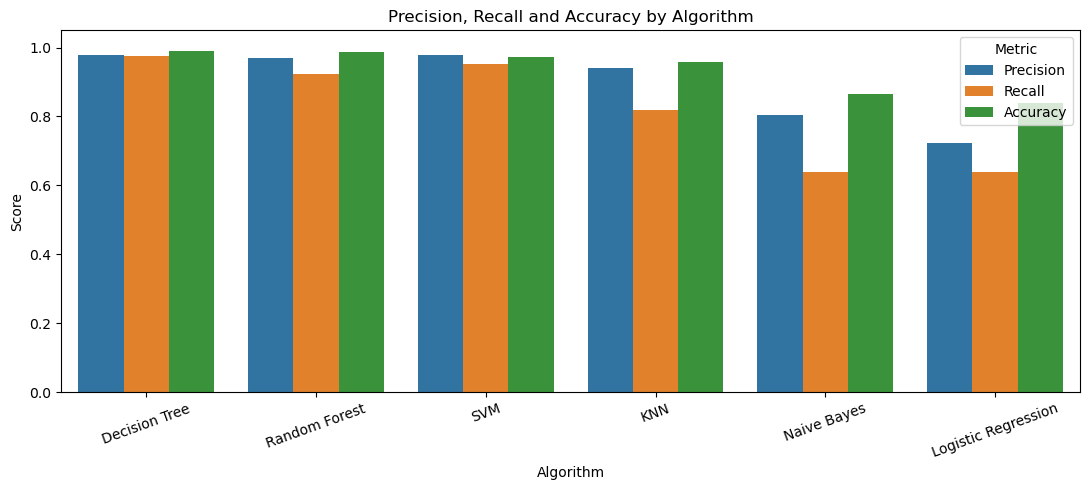

In [8]:
df_melt = df_results.melt(id_vars="Algorithm",
                          value_vars=["Precision", "Recall", "Accuracy"],
                          var_name="Metric", value_name="Score")

plt.figure(figsize=(11, 5))
sns.barplot(data=df_melt, x="Algorithm", y="Score", hue="Metric")
plt.title("Precision, Recall and Accuracy by Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### Confusion matrix of Best Model

Best model (by test accuracy): Decision Tree

--- Classification Report ---
              precision    recall  f1-score   support

         acc       0.97      0.99      0.98        77
        good       0.93      1.00      0.97        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.99       346
   macro avg       0.98      0.98      0.98       346
weighted avg       0.99      0.99      0.99       346



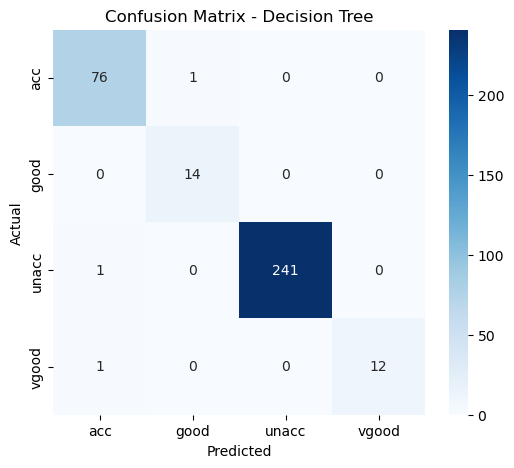

In [9]:
best_name = df_results.loc[0, "Algorithm"]
print("Best model (by test accuracy):", best_name)
y_pred_best = predictions[best_name]

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_best, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

#### Confusion Matrices  for all Models

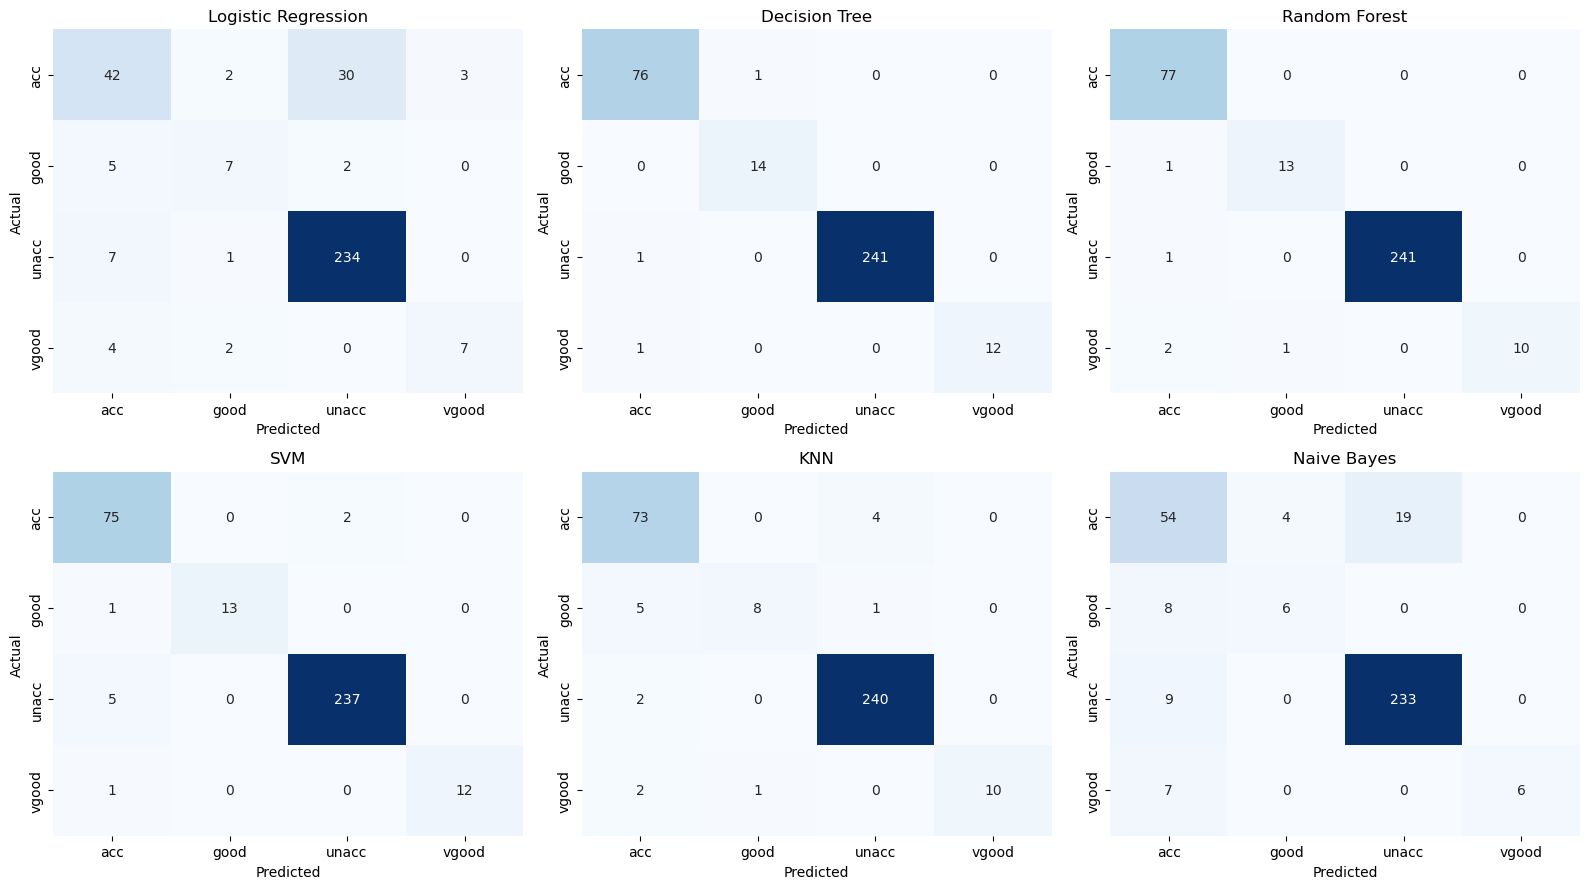

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### 
**Conclusion:** The Decision Tree gave the best performance on the Car Evaluation dataset, with an accuracy of about 0.99, macro precision of 0.98 and macro recall of 0.98, and it also had the highest cross-validation accuracy (0.986). Random Forest and SVM were also strong (accuracy 0.97-0.99). KNN performed reasonably but had lower recall on the rare classes, while Logistic Regression and Naive Bayes performed worst, because the data is categorical and rule-based, with interactions between features that linear models and the independence assumption cannot capture. Hence, the Decision Tree is the most suitable classifier for this problem